In [1]:
%pip install -q xgboost

In [2]:
import pandas as pd
import numpy as np

from sklearn.metrics import mean_squared_error, root_mean_squared_error, r2_score, mean_absolute_error

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Lasso
from sklearn.svm import SVR
from xgboost import XGBRegressor

import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
X_train = pd.read_csv('X_train_cyto.csv')
X_test = pd.read_csv('X_test_cyto.csv')
y_train = pd.read_csv('y_train_cyto.csv')
y_test = pd.read_csv('y_test_cyto.csv')

# Drop sn
X_train = X_train.drop('sn', axis=1)
X_test = X_test.drop('sn', axis=1)

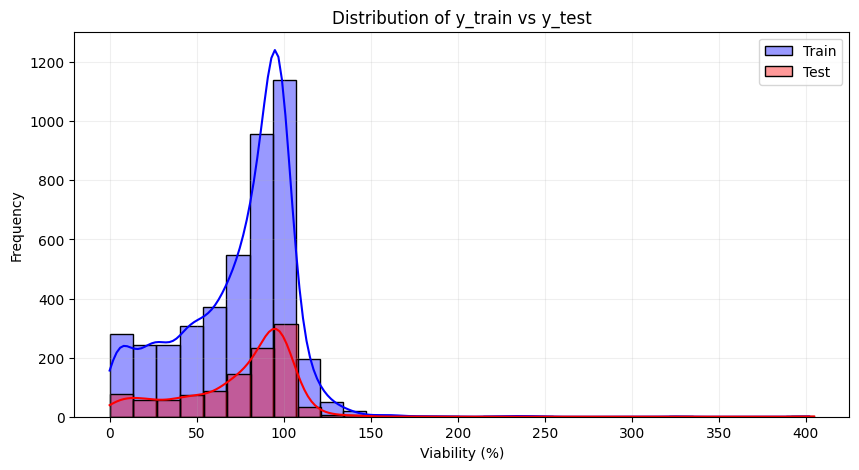

In [4]:
plt.figure(figsize=(10, 5))

sns.histplot(y_train.squeeze(), bins=30, color='blue',
             label='Train', alpha=0.4, kde=True)

sns.histplot(y_test.squeeze(), bins=30, color='red',
             label='Test', alpha=0.4, kde=True)

plt.xlabel('Viability (%)')
plt.ylabel('Frequency')
plt.title('Distribution of y_train vs y_test')
plt.legend()
plt.grid(alpha=0.2)

plt.show()

In [5]:
# Identify feature types
num_cols = X_train.select_dtypes(include=np.number).columns.tolist()
cat_cols = X_train.select_dtypes(exclude=np.number).columns.tolist()

In [6]:
# Preprocessing
numeric_transformer = SimpleImputer(strategy='median')

categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])
preprocessor = ColumnTransformer([
    ('num', numeric_transformer, num_cols),
    ('cat', categorical_transformer, cat_cols)
])

In [7]:
models = {
    'Random Forest': RandomForestRegressor(
        n_estimators=300,
        max_depth=None,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    'Lasso': Lasso(
        alpha=0.1,
        max_iter=10000
    ),

    'XGBoost': XGBRegressor(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=-1
    ),

    'SVR': SVR(
        kernel='rbf',
        C=10,
        epsilon=0.1,
        gamma='scale'
    )
}

In [8]:
results = {}
predictions = {}

for name, model in models.items():

    pipeline = Pipeline([
        ('preprocessing', preprocessor),
        ('model', model)
    ])

    pipeline.fit(X_train, y_train)

    pred = pipeline.predict(X_test)

    # Ensure positive viability predictions
    pred = np.maximum(pred, 0.000001)

    results[name] = pipeline
    predictions[name] = pred

    print(f"{name}: Training completed")

/usr/local/lib/python3.13/dist-packages/sklearn/base.py:1389: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


Random Forest: Training completed
Lasso: Training completed
XGBoost: Training completed


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


SVR: Training completed


In [9]:
evaluation = []

for name, pred in predictions.items():

    evaluation.append({
        'Model': name,
        'MAE': mean_absolute_error(y_test, pred),
        'MSE': mean_squared_error(y_test, pred),
        'RMSE': np.sqrt(mean_squared_error(y_test, pred)),
        'R2': r2_score(y_test, pred)
    })

evaluation_df = pd.DataFrame(evaluation)
evaluation_df = evaluation_df.sort_values('RMSE', ascending=True)
print(evaluation_df)

           Model        MAE          MSE       RMSE        R2
0  Random Forest  11.753865   358.320321  18.929351  0.660677
2        XGBoost  12.993085   377.735657  19.435423  0.642291
1          Lasso  19.425171   720.217156  26.836862  0.317966
3            SVR  23.655471  1126.492345  33.563259 -0.066769


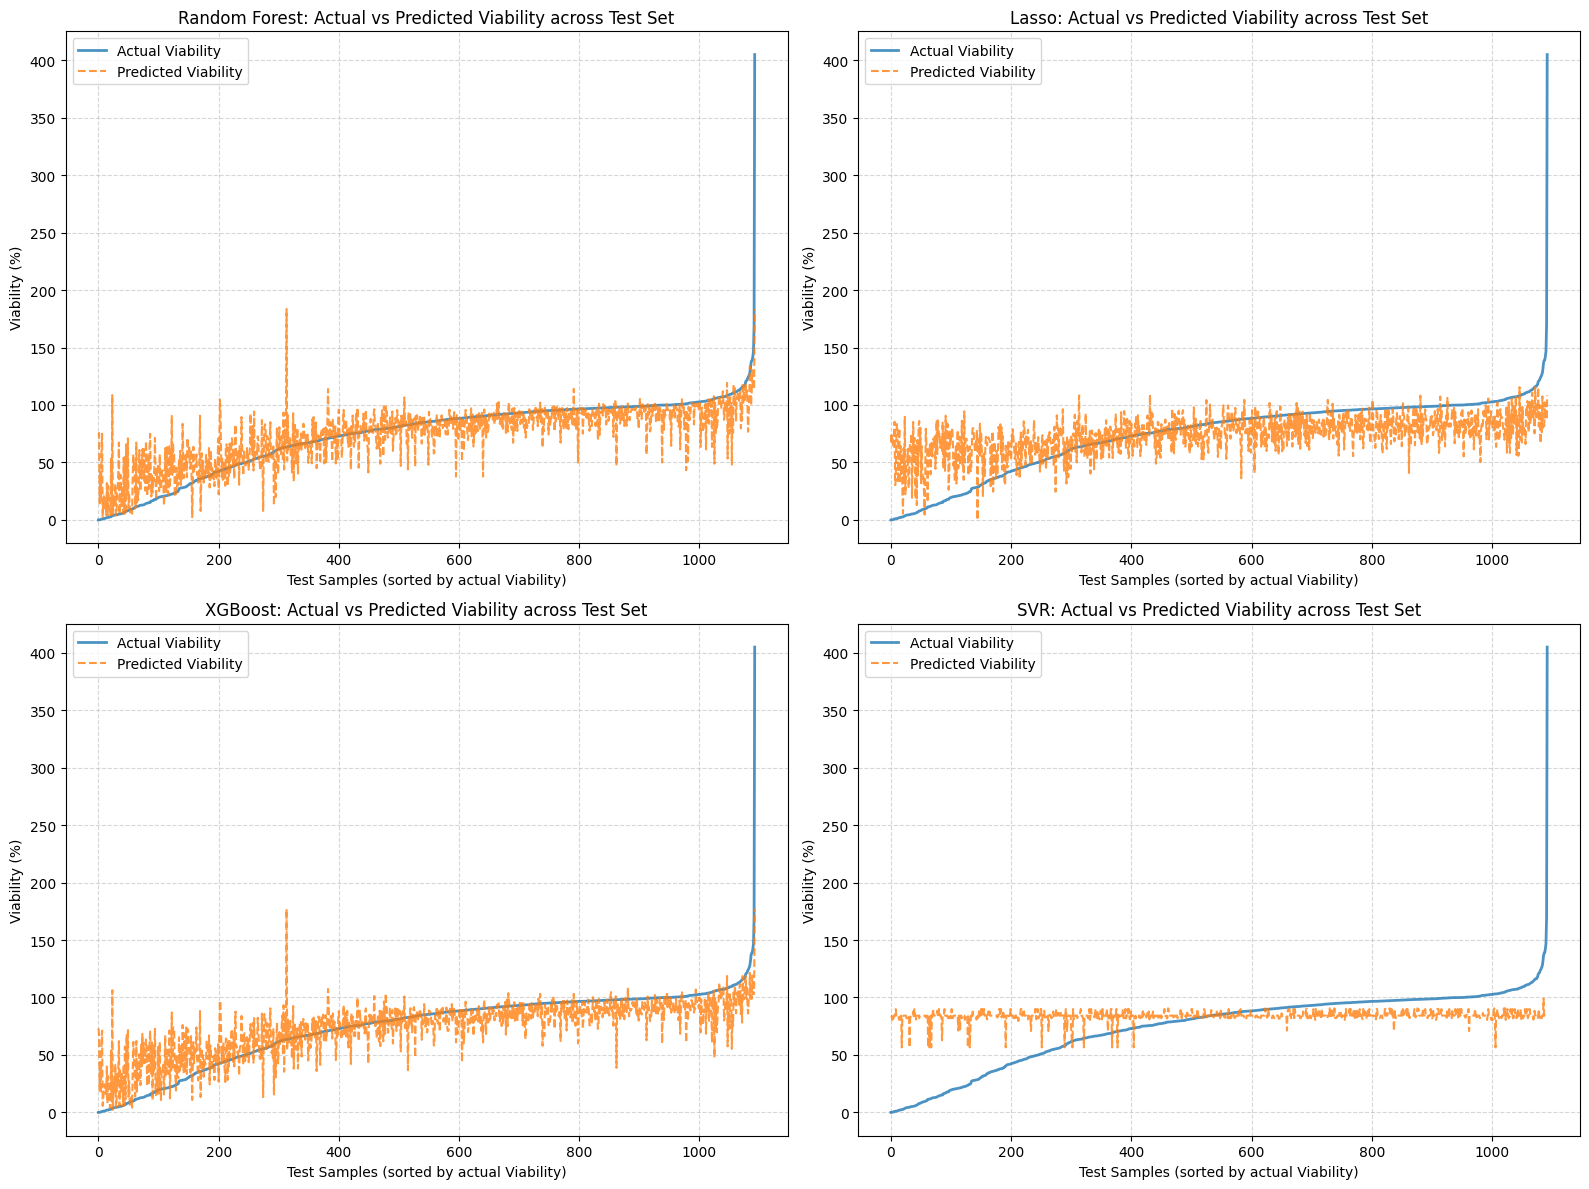

In [10]:
y_actual = y_test.squeeze().values if hasattr(y_test, 'squeeze') else np.array(y_test)
sorted_indices = np.argsort(y_actual)
y_actual_sorted = y_actual[sorted_indices]

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.ravel()

for idx, (name, pred) in enumerate(predictions.items()):
    ax = axes[idx]
    pred_sorted = np.array(pred)[sorted_indices]

    ax.plot(y_actual_sorted, label='Actual Viability', linestyle='-', linewidth=2, alpha=0.8)
    ax.plot(pred_sorted, label='Predicted Viability', linestyle='--', linewidth=1.5, alpha=0.8)

    ax.set_title(f'{name}: Actual vs Predicted Viability across Test Set')
    ax.set_xlabel('Test Samples (sorted by actual Viability)')
    ax.set_ylabel('Viability (%)')
    ax.legend()
    ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

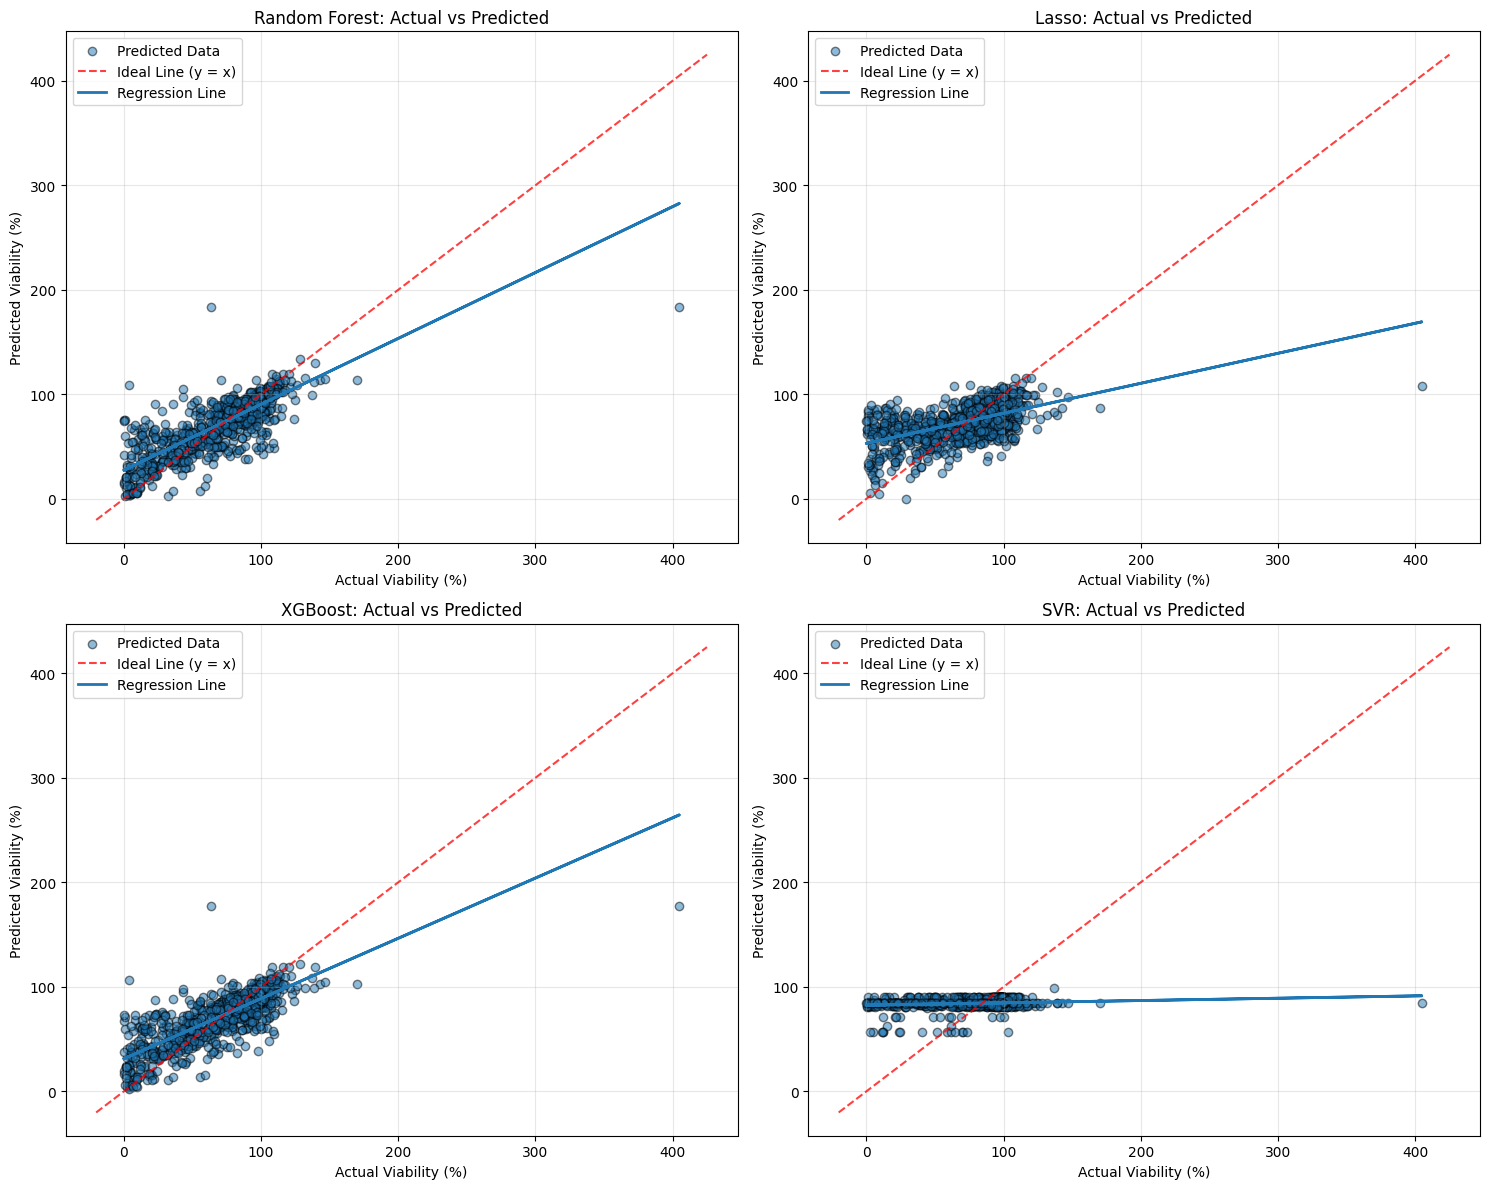

In [11]:
# Set up the subplot grid
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
axes = axes.ravel()

y_actual = y_test.squeeze()

for idx, (name, pred) in enumerate(predictions.items()):
    ax = axes[idx]
    # Plot actual vs predicted values
    ax.scatter(y_actual, pred, alpha=0.5, edgecolors='k', label='Predicted Data')
    # Plot the ideal line (y = x)
    lims = [
        np.min([ax.get_xlim(), ax.get_ylim()]),
        np.max([ax.get_xlim(), ax.get_ylim()])
    ]
    ax.plot(lims, lims, 'r--', alpha=0.75, zorder=3, label='Ideal Line (y = x)')
    # Plot the actual regression line
    m, b = np.polyfit(y_actual, pred, 1)
    ax.plot(y_actual, m * y_actual + b, linestyle='-', linewidth=2, label='Regression Line')
    ax.set_xlabel('Actual Viability (%)')
    ax.set_ylabel('Predicted Viability (%)')
    ax.set_title(f'{name}: Actual vs Predicted')
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [12]:
evaluation_df.to_csv('overallresult_ml_cyto_viability.csv', index=False)

In [13]:
quantiles = np.percentile(y_actual, [25, 50, 75])

def get_quantile_group(val):
    if val <= quantiles[0]:
        return 'Q1 (0-25%)'
    elif val <= quantiles[1]:
        return 'Q2 (25-50%)'
    elif val <= quantiles[2]:
        return 'Q3 (50-75%)'
    else:
        return 'Q4 (75-100%)'

groups = np.array([get_quantile_group(v) for v in y_actual])

quantile_evaluation = []

for name, pred in predictions.items():
    for group in ['Q1 (0-25%)', 'Q2 (25-50%)', 'Q3 (50-75%)', 'Q4 (75-100%)']:
        mask = (groups == group)
        if np.sum(mask) > 0:
            y_true_g = y_actual[mask]
            y_pred_g = np.array(pred)[mask]

            mae = mean_absolute_error(y_true_g, y_pred_g)
            mse = mean_squared_error(y_true_g, y_pred_g)
            rmse = np.sqrt(mean_squared_error(y_true_g, y_pred_g))
            r2 = r2_score(y_true_g, y_pred_g) if len(y_true_g) > 1 else np.nan

            via_min = np.min(y_true_g)
            via_max = np.max(y_true_g)
            via_range = f"{via_min:.2f} - {via_max:.2f}"

            quantile_evaluation.append({
                'Model': name,
                'Quantile': group,
                'N': np.sum(mask),
                'Viability range': via_range,
                'MAE': mae,
                'MSE': mse,
                'RMSE': rmse,
                'R2': r2
            })

quantile_eval_df = pd.DataFrame(quantile_evaluation)
display(quantile_eval_df)

,Model,Quantile,N,Viability range,MAE,MSE,RMSE,R2
0,Random Forest,Q1 (0-25%),274,0.00 - 55.19,18.247712,642.973291,25.356918,-1.218951
1,Random Forest,Q2 (25-50%),273,55.32 - 85.19,10.186499,233.942090,15.295166,-2.626604
2,Random Forest,Q3 (50-75%),273,85.19 - 96.97,7.629388,124.832643,11.172853,-9.477367
3,Random Forest,Q4 (75-100%),273,96.99 - 404.81,10.928076,430.490573,20.748267,-0.046576
4,Lasso,Q1 (0-25%),274,0.00 - 55.19,33.321218,1552.039957,39.395938,-4.356211
5,Lasso,Q2 (25-50%),273,55.32 - 85.19,10.364549,171.620933,13.100417,-1.660492
6,Lasso,Q3 (50-75%),273,85.19 - 96.97,13.302580,267.505238,16.355587,-21.452064
7,Lasso,Q4 (75-100%),273,96.99 - 404.81,20.661436,886.655525,29.776762,-1.155570
8,XGBoost,Q1 (0-25%),274,0.00 - 55.19,20.272039,700.812219,26.472858,-1.418557
9,XGBoost,Q2 (25-50%),273,55.32 - 85.19,9.964370,214.336152,14.640224,-2.322670


In [14]:
quantile_eval_df.to_csv('quantileresult_ml_cyto_viability.csv', index=False)

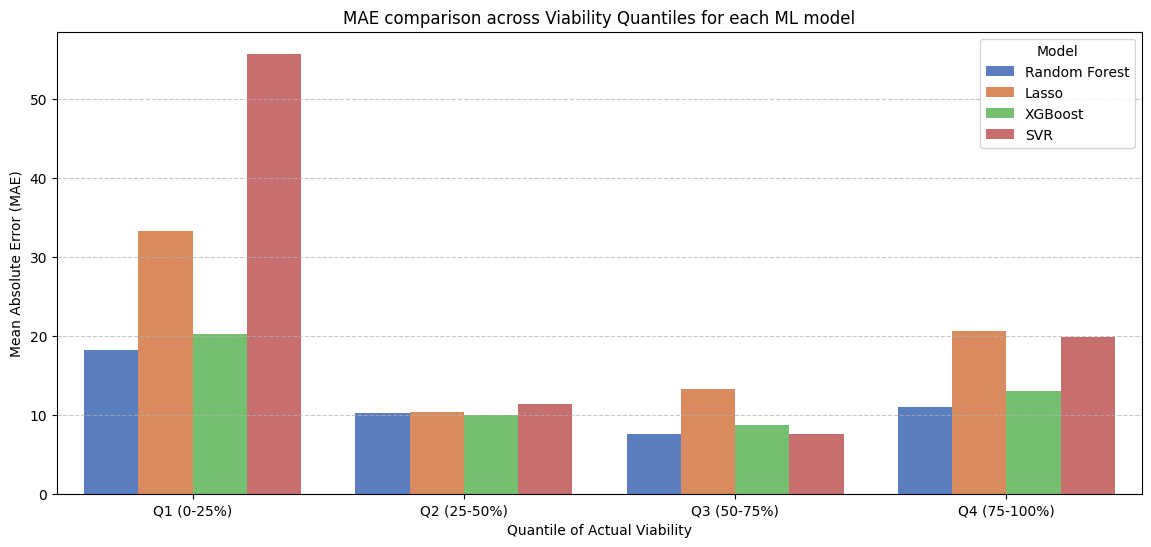

In [15]:
plt.figure(figsize=(14, 6))
sns.barplot(data=quantile_eval_df, x='Quantile', y='MAE', hue='Model', palette='muted')
plt.title('MAE comparison across Viability Quantiles for each ML model')
plt.xlabel('Quantile of Actual Viability')
plt.ylabel('Mean Absolute Error (MAE)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

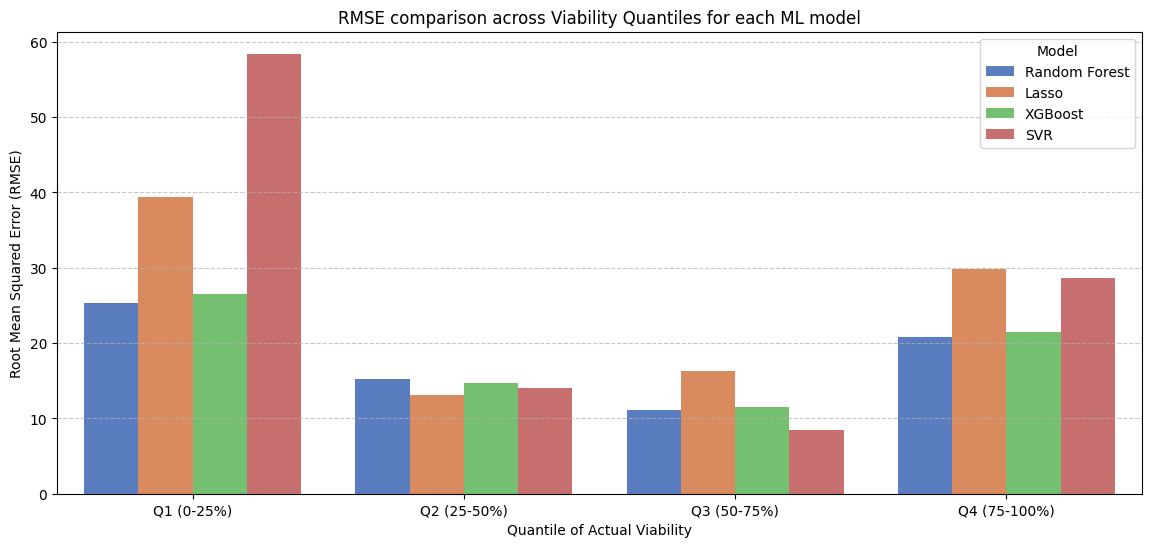

In [16]:
plt.figure(figsize=(14, 6))
sns.barplot(data=quantile_eval_df, x='Quantile', y='RMSE', hue='Model', palette='muted')
plt.title('RMSE comparison across Viability Quantiles for each ML model')
plt.xlabel('Quantile of Actual Viability')
plt.ylabel('Root Mean Squared Error (RMSE)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()